## 1. Import Basic Libraries

In [1]:
#Import basic Libraries
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.impute import SimpleImputer

## 2. Load Data

In [2]:
#Load Data
test = pd.read_csv('test.csv')
train = pd.read_csv('train.csv')

## 3. Basic Data Exploration

**컬럼 의미**

| 컬럼 | 의미 |
|---|---|
| `PassengerId` | `그룹번호_그룹내번호` 형식의 승객 ID |
| `HomePlanet` | 출발 행성 |
| `CryoSleep` | 냉동 수면 여부 |
| `Cabin` | `데크/번호/좌우(P·S)` 형식의 객실 |
| `Destination` | 도착지 |
| `Age`, `VIP` | 나이, VIP 여부 |
| `RoomService`, `FoodCourt`, `ShoppingMall`, `Spa`, `VRDeck` | 각 편의시설 지출액 |
| `Name` | 이름 |
| `Transported` | **타깃**. 다른 차원으로 이동했는지 여부 |

In [3]:
#Load the test Data
test.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name
0,0013_01,Earth,True,G/3/S,TRAPPIST-1e,27.0,False,0.0,0.0,0.0,0.0,0.0,Nelly Carsoning
1,0018_01,Earth,False,F/4/S,TRAPPIST-1e,19.0,False,0.0,9.0,0.0,2823.0,0.0,Lerome Peckers
2,0019_01,Europa,True,C/0/S,55 Cancri e,31.0,False,0.0,0.0,0.0,0.0,0.0,Sabih Unhearfus
3,0021_01,Europa,False,C/1/S,TRAPPIST-1e,38.0,False,0.0,6652.0,0.0,181.0,585.0,Meratz Caltilter
4,0023_01,Earth,False,F/5/S,TRAPPIST-1e,20.0,False,10.0,0.0,635.0,0.0,0.0,Brence Harperez


In [4]:
#Load the train Data
train.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [5]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   str    
 1   HomePlanet    8492 non-null   str    
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   str    
 4   Destination   8511 non-null   str    
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   str    
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(2), str(5)
memory usage: 891.5+ KB


In [6]:
#Percentage of missing values in the dataset
missing_percentage = (train.isnull().sum() / len(train)) * 100
print(missing_percentage)

PassengerId     0.000000
HomePlanet      2.312205
CryoSleep       2.496261
Cabin           2.289198
Destination     2.093639
Age             2.059128
VIP             2.335212
RoomService     2.082135
FoodCourt       2.105142
ShoppingMall    2.392730
Spa             2.105142
VRDeck          2.162660
Name            2.300702
Transported     0.000000
dtype: float64


In [7]:
#Percentage of missing values in the dataset
missing_percentage = (test.isnull().sum() / len(test)) * 100
print(missing_percentage)

PassengerId     0.000000
HomePlanet      2.034136
CryoSleep       2.174421
Cabin           2.338087
Destination     2.151040
Age             2.127660
VIP             2.174421
RoomService     1.917232
FoodCourt       2.478373
ShoppingMall    2.291326
Spa             2.361468
VRDeck          1.870470
Name            2.197802
dtype: float64


- 학습 데이터는 8,693건, 테스트 데이터는 4,277건이다.
- `PassengerId`와 `Transported`를 제외한 모든 컬럼에 약 2%의 결측치가 있다. 학습과 테스트의 결측 비율이 비슷하다.

## 4. Exploratory Data Analysis

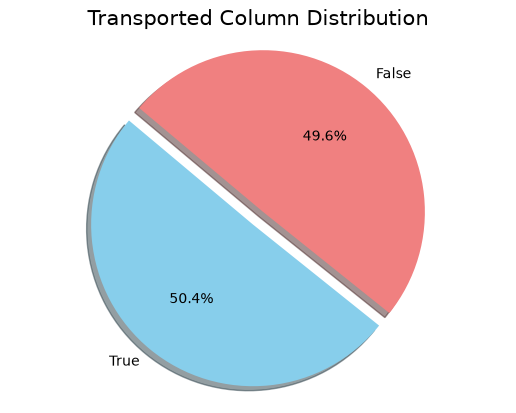

In [8]:
true_count = train['Transported'].sum()
false_count = len(train) - true_count

# Data for the pie chart
labels = ['True', 'False']
sizes = [true_count, false_count]
colors = ['skyblue', 'lightcoral']
explode = (0.1, 0)

# Create the pie chart
plt.pie(sizes, explode=explode, labels=labels, colors=colors,
autopct='%1.1f%%', shadow=True, startangle=140)


plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
plt.title("Transported Column Distribution", size = 15)
plt.show()

- 타깃의 True 비율이 50.4%로 거의 균등하다. 따라서 정확도를 평가 지표로 써도 무리가 없으며, 대회의 평가 지표도 정확도이다.
- `explode`는 조각을 중심에서 떼어 내는 정도, `autopct`는 비율 표시 형식을 지정하는 인자이다.

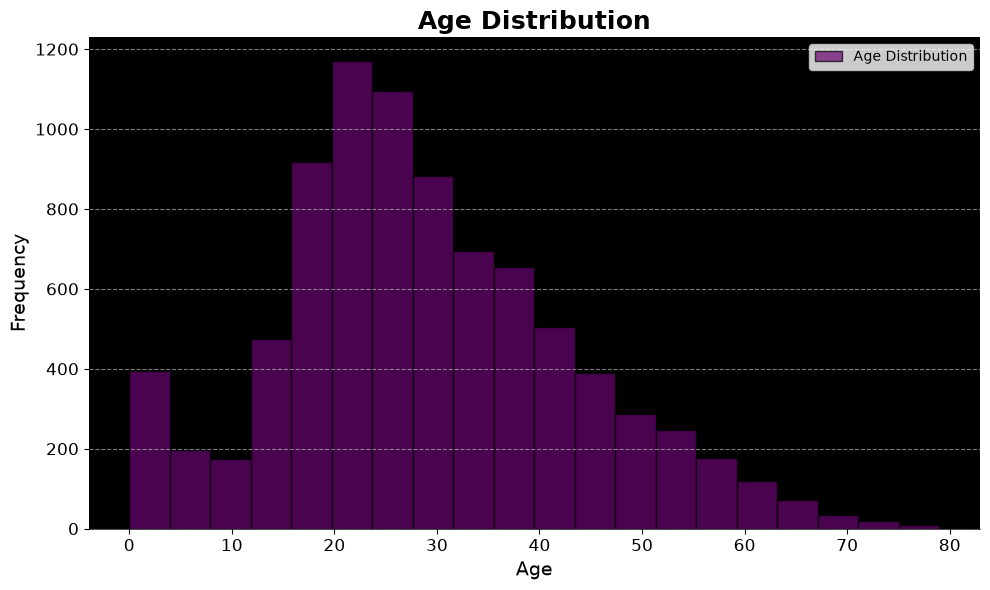

In [9]:
age_data = train['Age']

plt.figure(figsize=(10, 6))
plt.hist(age_data, bins=20, edgecolor='black', color='#6A0572', alpha=0.7, label='Age Distribution')

plt.title('Age Distribution', fontsize=18, fontweight='bold', color='black')
plt.xlabel('Age', fontsize=14, color='black')
plt.ylabel('Frequency', fontsize=14, color='black')

plt.xticks(fontsize=12, color='black')
plt.yticks(fontsize=12, color='black')
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.gca().set_facecolor('black')

# Remove unnecessary spines and set the layout
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['left'].set_linewidth(0.5)
plt.gca().spines['bottom'].set_linewidth(0.5)

# Add legend
plt.legend()

plt.tight_layout()

plt.show()

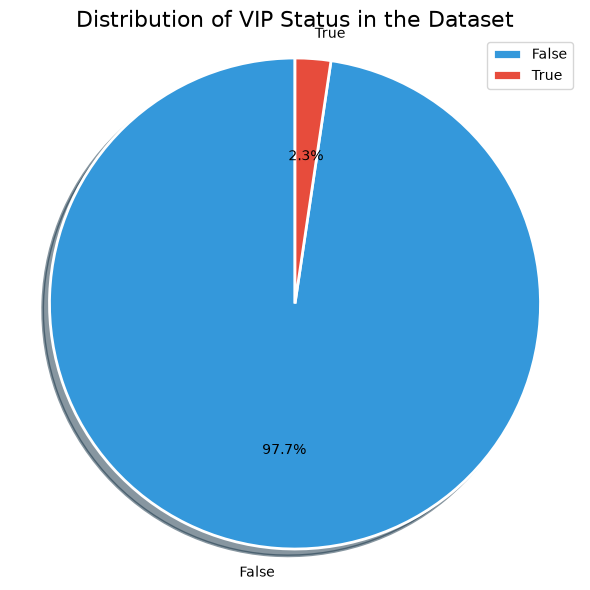

In [10]:
sex_counts = train['VIP'].value_counts()
colors = ['#3498db', '#e74c3c']

# Create the pie chart
plt.figure(figsize=(6, 6))
plt.pie(sex_counts, labels=sex_counts.index, colors=colors, autopct='%1.1f%%', startangle=90, shadow=True, wedgeprops={'linewidth': 2, 'edgecolor': 'white'})

# Add a title and legend
plt.title("Distribution of VIP Status in the Dataset", fontsize=16)
plt.legend(labels=sex_counts.index, loc='upper right')

# Equal aspect ratio ensures that pie is drawn as a circle.
plt.axis('equal')

# Show the pie chart
plt.tight_layout()
plt.show()

- 나이는 중앙값 27세, 범위 0~79세이며 20대에 몰려 있다. 0세 승객도 178명 있다.
- VIP는 False가 97.7%로 매우 치우쳐 있다.
- 원본의 변수명 `sex_counts`는 VIP 개수를 담고 있다. 다른 노트북의 코드를 재사용하며 남은 이름으로 보이며, 필사이므로 그대로 두었다.

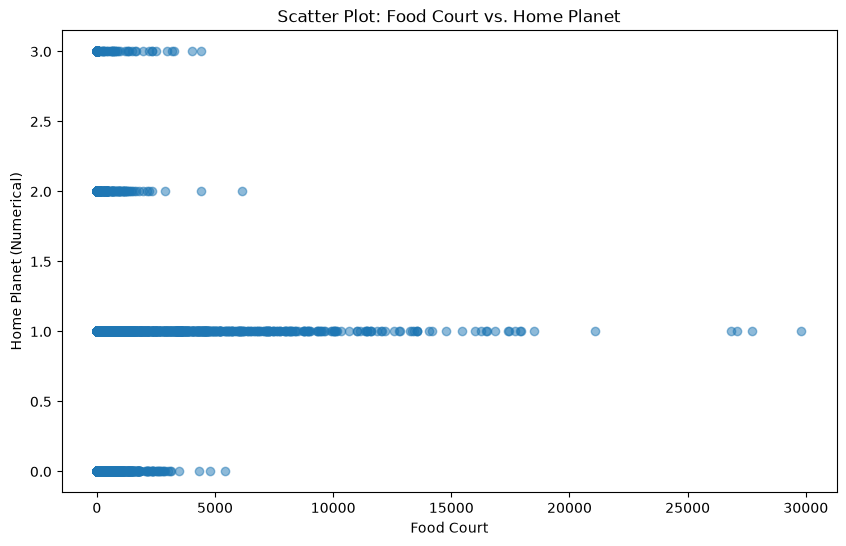

In [11]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder

food_court = train['FoodCourt']
home_planet = train['HomePlanet']


label_encoder = LabelEncoder()
home_planet_numerical = label_encoder.fit_transform(home_planet)

# Create a scatter plot
plt.figure(figsize=(10, 6))
plt.scatter(food_court, home_planet_numerical, alpha=0.5)


plt.xlabel('Food Court')
plt.ylabel('Home Planet (Numerical)')
plt.title('Scatter Plot: Food Court vs. Home Planet')

# Show the plot
plt.show()

- 세로축은 `LabelEncoder`로 바꾼 값으로, 0=Earth, 1=Europa, 2=Mars, 3=결측치이다.
- 결측치까지 하나의 클래스로 인코딩되어 3번 줄이 생긴 점에 주의한다.
- Europa 승객의 푸드코트 지출이 가장 크다(평균 약 1,503, 최대 29,813). 그래프에서도 1번 줄이 가장 멀리까지 뻗어 있다.

## 5. Data Preprocessing

범주형 컬럼을 `LabelEncoder`로 숫자로 바꾸고, 남은 결측치를 `SimpleImputer`의 중앙값으로 채우는 단계이다.

**이 코드에서 주의 깊게 볼 점**

- `RoomService` 등 지출액은 원래 숫자인데 범주형 목록에 들어 있다. 고유값을 작은 순서대로 정수로 바꾸므로 값의 크기 정보가 사라지고 순서만 남는다.
- 결측치도 하나의 클래스로 인코딩되며, 정렬 시 맨 뒤에 놓인다. 예를 들어 `RoomService`의 결측치는 가장 큰 코드인 1273이 되어 **가장 많이 지출한 사람처럼** 취급된다.
- 그 결과 인코딩 후 결측치가 남는 컬럼은 `Age`뿐이다(179건). 즉 `SimpleImputer`는 사실상 `Age`만 채운다.

In [12]:
categorical_columns = ['HomePlanet', 'CryoSleep', 'Cabin', 'Destination', 'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'Name']

# Create a LabelEncoder for each categorical column
label_encoders = {}
for col in categorical_columns:
    le = LabelEncoder()
    train[col] = le.fit_transform(train[col])
    label_encoders[col] = le

# Sample data with encoded categorical columns
X_categorical_encoded = train[['HomePlanet', 'CryoSleep', 'Cabin', 'Destination', 'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'Name']]
y = train['Transported']


# Concatenate the encoded categorical columns with other numerical columns
X_encoded = pd.concat([X_categorical_encoded, train[['Age']]], axis=1)

# Create an imputer with median strategy
imputer = SimpleImputer(strategy='median')

# Fit the imputer on the data and transform to fill missing values
X_imputed = imputer.fit_transform(X_encoded)

# Convert the imputed array back to a DataFrame with column names
X_imputed_df = pd.DataFrame(X_imputed, columns=X_encoded.columns)

# Assign the imputed DataFrame back to X
X = X_imputed_df

# Create a LabelEncoder for the target variable 'Transported'
label_encoder_y = LabelEncoder()
y_encoded = label_encoder_y.fit_transform(y)

# Assign the encoded target variable back to y
y = y_encoded

**`SelectKBest`와 `f_classif`**

- `f_classif`는 타깃 클래스별로 피처 평균이 얼마나 다른지를 ANOVA F-통계량으로 계산한다. 값이 클수록 클래스를 잘 구분하는 피처로 본다.
- `SelectKBest`는 점수가 높은 피처 k개를 고른다. 여기서는 `k='all'`이므로 실제로 피처를 제거하지 않고 점수만 확인한다.

In [13]:
import pandas as pd
from sklearn.feature_selection import SelectKBest, f_classif

selector = SelectKBest(score_func=f_classif, k='all')
X_new = selector.fit_transform(X, y)

# Print the selected features and their scores
selected_features = X.columns[selector.get_support()]
scores = selector.scores_[selector.get_support()]
feature_scores = list(zip(selected_features, scores))
print("Selected Features and their Scores:")
for feature, score in feature_scores:
    print(f"{feature}: {score:.2f}")

Selected Features and their Scores:
HomePlanet: 102.10
CryoSleep: 1702.38
Cabin: 24.12
Destination: 96.55
VIP: 1.77
RoomService: 725.48
FoodCourt: 0.44
ShoppingMall: 7.72
Spa: 708.32
VRDeck: 574.17
Name: 0.60
Age: 48.16


- `CryoSleep`(1702.38)이 가장 높다. 실제로 냉동 수면 승객의 이동 비율은 81.8%로, 그렇지 않은 승객의 32.9%보다 훨씬 높다.
- `RoomService`, `Spa`, `VRDeck`의 지출도 높은 점수를 보인다.
- `Name`(0.60)은 점수가 낮다. 이름은 승객마다 거의 달라 일반화할 패턴이 없으므로 예측에 쓰기 어렵다.
- `FoodCourt`(0.44)도 낮지만 바로 쓸모없다고 볼 수는 없다. F-통계량은 평균 차이만 보기 때문에 비선형 관계나 다른 피처와의 상호작용은 잡아내지 못한다.

## 6. Modelling

In [14]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.001, random_state=15)

In [15]:
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier()
model

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [16]:
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [17]:
model.score(X_test, y_test)

1.0

- 제목의 "100%"는 이 정확도 1.0을 가리킨다.
- 그러나 `test_size=0.001`은 전체의 0.1%만 검증에 쓴다는 뜻이다. 이 점수가 믿을 만한지는 8장에서 확인한다.

## 7. Submitting Predictions

In [18]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer

# Load the test dataset
test = pd.read_csv('test.csv')


# Apply the same LabelEncoder transformations to categorical columns
categorical_columns = ['HomePlanet', 'CryoSleep', 'Cabin', 'Destination', 'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'Name']

for col in categorical_columns:
    if col in label_encoders:
        le = label_encoders[col]
        # Transform test data and handle unknown categories by assigning a specific label (-1 in this case)
        test[col] = test[col].apply(lambda x: le.transform([x])[0] if x in le.classes_ else -1)

# Select the same columns as you did for training data
X_test_categorical_encoded = test[['HomePlanet', 'CryoSleep', 'Cabin', 'Destination', 'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'Name']]

# Concatenate the encoded categorical columns with other numerical columns
X_test_encoded = pd.concat([X_test_categorical_encoded, test[['Age']]], axis=1)

# Use the same imputer as in the training data
imputer = SimpleImputer(strategy='median')
X_test_imputed = imputer.fit_transform(X_test_encoded)

# Convert the imputed array back to a DataFrame with column names
X_test_imputed_df = pd.DataFrame(X_test_imputed, columns=X_test_encoded.columns)

# Now, X_test_imputed_df contains the preprocessed test data

# Make predictions on the test data using your trained model
predictions = model.predict(X_test_imputed_df)  # Replace 'model' with your trained model

# Create a submission DataFrame
submission = pd.DataFrame({'PassengerId': test['PassengerId'], 'Transported': predictions})

In [19]:
target_map = {0: 'False', 1: 'True'}

final_df = pd.DataFrame(submission)
final_df['Transported'] = pd.Series(predictions).map(target_map)
final_df.to_csv('submission.csv', index=False)

In [20]:
final_df

,PassengerId,Transported
0,0013_01,True
1,0018_01,False
2,0019_01,True
3,0021_01,False
4,0023_01,True
...,...,...
4272,9266_02,True
4273,9269_01,True
4274,9271_01,True
4275,9273_01,True


- 원본 주석은 "같은 변환을 적용한다"고 되어 있지만, 학습 때 없던 값은 `else -1` 분기로 모두 -1이 된다.
- `x in le.classes_`에서 `NaN`은 자기 자신과도 같지 않으므로 결측치도 -1이 된다. 학습 때는 가장 큰 코드였던 결측치가 테스트에서는 -1이 되어 **학습과 테스트의 인코딩이 일치하지 않는다.**
- 원본 주석에는 "같은 imputer"라고 되어 있지만 실제로는 새 `SimpleImputer`를 만들어 테스트 데이터에 다시 `fit`한다. 올바른 방법은 학습 때 `fit`한 객체의 `transform`만 호출하는 것이다.

## 8. 추가 확인: 100%와 0.696의 차이

> 이 장은 필사 범위 밖이며, 직접 작성한 코드이다.

검증 정확도는 1.0인데 Public Score는 0.69628이다. 차이가 생긴 원인을 단계별로 확인한다.

### 8-1. 검증 데이터의 크기

In [21]:
print('검증 데이터 건수:', len(X_test))
print('1건을 틀렸을 때의 정확도: {0:.4f}'.format((len(X_test) - 1) / len(X_test)))

검증 데이터 건수: 9
1건을 틀렸을 때의 정확도: 0.8889


검증 데이터가 9건뿐이다. 1건만 틀려도 0.8889로 떨어지므로 정확도 1.0은 성능을 판단할 근거가 되지 못한다.

### 8-2. 교차 검증

In [22]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(RandomForestClassifier(random_state=15), X, y, cv=5)
print('5-Fold 정확도:', np.round(cv_scores, 4))
print('평균 정확도: {0:.4f}'.format(cv_scores.mean()))

5-Fold 정확도: [0.774  0.7706 0.7872 0.7865 0.7934]
평균 정확도: 0.7824


- 5-Fold 평균 정확도는 약 0.782로, 1.0보다 훨씬 낮다. 이 값이 모델의 성능에 더 가깝다.
- 그래도 Public Score 0.696과는 차이가 크다. 이 `X`는 분할 전에 전체 학습 데이터로 인코딩되었으므로, 검증 폴드에도 "처음 보는 값"이 나타나지 않는다. 실제 테스트 상황과 조건이 다른 것이다.

### 8-3. 테스트 데이터에서 -1이 된 비율

In [23]:
print('제출 데이터에서 -1로 인코딩된 비율')
print((test[categorical_columns] == -1).mean().round(4))

제출 데이터에서 -1로 인코딩된 비율
HomePlanet      0.0203
CryoSleep       0.0217
Cabin           1.0000
Destination     0.0215
VIP             0.0217
RoomService     0.1024
FoodCourt       0.1398
ShoppingMall    0.0928
Spa             0.1178
VRDeck          0.1038
Name            0.9953
dtype: float64


- `Cabin`은 **100%**, `Name`은 99.5%가 -1이다. 학습과 테스트에 겹치는 객실이 하나도 없어, 테스트에서 `Cabin`은 정보가 전혀 없는 컬럼이 된다.
- 지출액 컬럼도 약 9~14%가 -1이다(결측치 약 2% 포함). 학습에 없던 금액이면 금액이 아무리 커도 -1이 되어, 지출이 없는 사람(코드 0)보다도 작은 값으로 들어간다.
- 지출액은 약 61~64%가 0원이므로, 지출이 있는 승객만 놓고 보면 영향받는 비율은 이보다 훨씬 크다.

### 8-4. 원본과 같은 전처리로 실제 상황 재현

학습 데이터를 8:2로 먼저 나누고, 8 쪽에서만 인코더를 학습한 뒤 2 쪽에는 원본의 7장과 똑같이 적용한다. 이렇게 하면 검증 쪽에 "처음 보는 값"이 생겨 실제 테스트와 같은 조건이 된다.

In [24]:
from sklearn.metrics import accuracy_score

raw_train = pd.read_csv('train.csv')
fit_df, val_df = train_test_split(raw_train, test_size=0.2, random_state=15)
fit_df, val_df = fit_df.copy(), val_df.copy()

for col in categorical_columns:
    le = LabelEncoder()
    fit_df[col] = le.fit_transform(fit_df[col])
    val_df[col] = val_df[col].apply(lambda x: le.transform([x])[0] if x in le.classes_ else -1)

feature_columns = categorical_columns + ['Age']
X_fit = SimpleImputer(strategy='median').fit_transform(fit_df[feature_columns])
X_val = SimpleImputer(strategy='median').fit_transform(val_df[feature_columns])

same_way_model = RandomForestClassifier(random_state=15)
same_way_model.fit(X_fit, fit_df['Transported'])
same_way_accuracy = accuracy_score(val_df['Transported'], same_way_model.predict(X_val))
print('원본과 같은 전처리의 검증 정확도: {0:.4f}'.format(same_way_accuracy))

원본과 같은 전처리의 검증 정확도: 0.7056


- 정확도가 0.7056으로, 교차 검증 0.782보다 크게 낮고 **Public Score 0.69628에 가깝다.**
- 즉 점수 하락의 주된 원인은 모델이 아니라 **학습과 테스트에서 값이 어긋나는 전처리**로 볼 수 있다.

### 8-5. 전처리를 고친 결과

다음 네 가지만 바꾸고 모델은 그대로 둔다.

1. 지출액과 나이는 숫자 그대로 쓰고, 결측치는 학습 데이터의 중앙값으로 채운다.
2. `Name`을 제외한다.
3. `Cabin`을 `Deck`과 `Side`로 나눈다. 데크와 좌우는 테스트에도 같은 값이 나온다.
4. 인코더와 imputer는 학습 쪽에서만 `fit`하고, 검증 쪽에는 `transform`만 적용한다.

In [25]:
from sklearn.preprocessing import OrdinalEncoder

numeric_columns = ['Age', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']
category_columns = ['HomePlanet', 'CryoSleep', 'Destination', 'VIP', 'Deck', 'Side']


def split_cabin(df):
    result = df.copy()
    result[['Deck', 'CabinNum', 'Side']] = result['Cabin'].str.split('/', expand=True)
    result[category_columns] = result[category_columns].astype(object).fillna('Missing').astype(str)
    return result


fit_df, val_df = train_test_split(raw_train, test_size=0.2, random_state=15)
fit_df, val_df = split_cabin(fit_df), split_cabin(val_df)

numeric_imputer = SimpleImputer(strategy='median')
category_encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)

X_fit = np.hstack([numeric_imputer.fit_transform(fit_df[numeric_columns]),
                   category_encoder.fit_transform(fit_df[category_columns])])
X_val = np.hstack([numeric_imputer.transform(val_df[numeric_columns]),
                   category_encoder.transform(val_df[category_columns])])

fixed_model = RandomForestClassifier(random_state=15)
fixed_model.fit(X_fit, fit_df['Transported'])
fixed_accuracy = accuracy_score(val_df['Transported'], fixed_model.predict(X_val))
print('전처리를 고친 뒤의 검증 정확도: {0:.4f}'.format(fixed_accuracy))

전처리를 고친 뒤의 검증 정확도: 0.7849


- 같은 조건의 검증에서 정확도가 0.7056에서 **0.7849**로 올랐다. 하이퍼 파라미터 튜닝 없이 전처리만 고친 결과이다.
- 다만 이 값은 학습 데이터 안에서 나눈 검증 점수이며, Kaggle에 제출해 얻은 점수는 아니다.